## Hypothesis Check: Correlation vs Edge Betweenness
Hypothesis: With increasing value of correlation for an edge, the edge betweenness also increases.

**Scope**: All subjects, all sessions, all segments (individual segment matrices, no averaging).

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

abs_segment_base = Path('correlation_matrices_segment_wise_absolute')
csv_files = list(abs_segment_base.rglob('*.csv'))

# We will collect correlation and betweenness values across all subjects
correlation_values = []
betweenness_values = []

for idx, csv_file in enumerate(csv_files):
    if idx % 500 == 0:
        print(f"Processed {idx}/{len(csv_files)} files...")
        
    df = pd.read_csv(csv_file, index_col=0)
    
    # Create Graph
    G = nx.from_pandas_adjacency(df)
    
    # Calculate distance
    for u, v, d in G.edges(data=True):
        weight = d.get('weight', 0)
        if weight > 0:
            d['distance'] = 1.0 / weight
        else:
            d['distance'] = np.inf
            
    # Calculate betweenness centrality
    eb = nx.edge_betweenness_centrality(G, weight='distance')
    
    # Store correlation and betweenness
    for (u, v), val in eb.items():
        corr = df.loc[u, v]
        correlation_values.append(corr)
        betweenness_values.append(val)

print(f"Done! Collected {len(correlation_values)} edge pairs from {len(csv_files)} segment matrices.")

Processed 0/2632 files...
Processed 500/2632 files...
Processed 1000/2632 files...
Processed 1500/2632 files...
Processed 2000/2632 files...
Processed 2500/2632 files...
Done! Collected 500080 edge pairs from 2632 segment matrices.


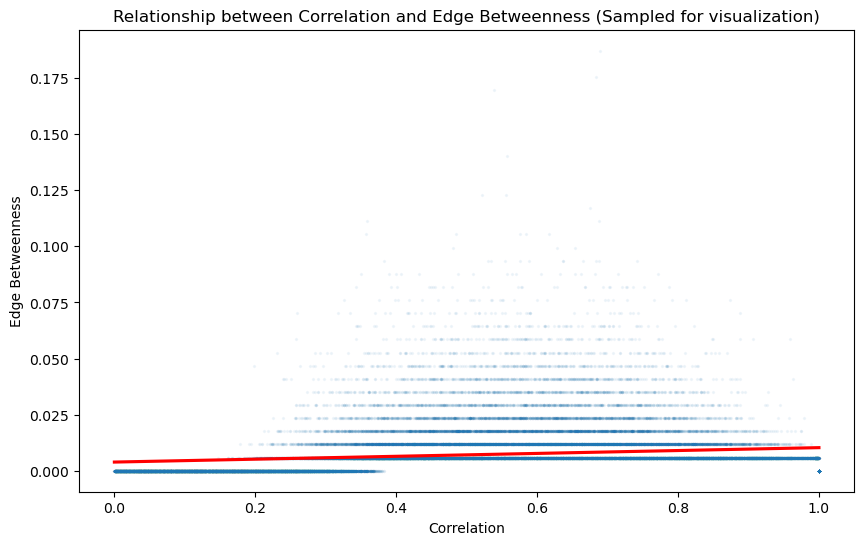

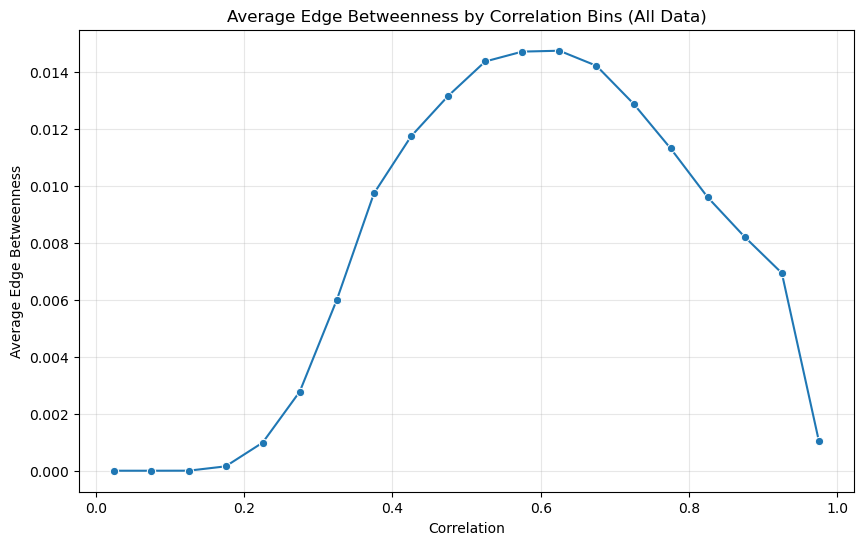

Pearson correlation coefficient between Correlation and Edge Betweenness: 0.1860


In [2]:
# Create a DataFrame for plotting
df_plot = pd.DataFrame({
    'Correlation': correlation_values,
    'Edge Betweenness': betweenness_values
})

# Plot 1: Scatter plot with linear regression line
# Given the massive number of points (approx 450,000), we sample for the scatter plot to speed up rendering.
df_sample = df_plot.sample(n=min(50000, len(df_plot)), random_state=42)

plt.figure(figsize=(10, 6))
sns.regplot(data=df_sample, x='Correlation', y='Edge Betweenness', scatter_kws={'alpha':0.05, 's':2}, line_kws={'color':'red'})
plt.title('Relationship between Correlation and Edge Betweenness (Sampled for visualization)')
plt.show()

# Plot 2: Binned Line Graph (using full data)
# Group correlations into bins to clearly see the trend as a line graph
df_plot['Correlation Bin'] = pd.cut(df_plot['Correlation'], bins=np.linspace(0, 1, 21))
bin_means = df_plot.groupby('Correlation Bin', observed=True)['Edge Betweenness'].mean().reset_index()
# Convert interval to mid-point for plotting
bin_means['Correlation Midpoint'] = bin_means['Correlation Bin'].apply(lambda x: x.mid).astype(float)

plt.figure(figsize=(10, 6))
sns.lineplot(data=bin_means, x='Correlation Midpoint', y='Edge Betweenness', marker='o')
plt.title('Average Edge Betweenness by Correlation Bins (All Data)')
plt.xlabel('Correlation')
plt.ylabel('Average Edge Betweenness')
plt.grid(True, alpha=0.3)
plt.show()

# Calculate Pearson correlation coefficient on full dataset
pearson_corr = df_plot['Correlation'].corr(df_plot['Edge Betweenness'])
print(f"Pearson correlation coefficient between Correlation and Edge Betweenness: {pearson_corr:.4f}")


# deduction : hypothesis is wrong

When two regions have an extraordinarily high correlation (e.g., > 0.8), they are likely part of the same dense local cluster (a clique). In network science, edges inside a dense local cluster have very low betweenness because there are many redundant paths between those nodes. They aren't "bridges" connecting different communities; they are just internal wires within a single community. The true "bridges" (highest betweenness) are the edges with moderately strong correlations (~0.6) that connect distinct, separate functional clusters.

Edge betweenness increases with correlation up to a critical threshold (~0.6), indicating these moderately strong connections act as primary bridges between different brain networks. However, at extremely high correlations (>0.6), betweenness decreases, reflecting edges that are heavily embedded within isolated local clusters rather than acting as global bridges.